# Case Study: Wine Quality Assessment Using Physicochemical Properties

**Goal:** find which laboratory measurements are most strongly associated with sensory wine quality, and test whether a multiple linear regression can predict the quality score.

**Data:** Vinho Verde red (1,599 rows) and white (4,898 rows) wines, Cortez et al. (2009). 11 physicochemical inputs, `quality` (0-10, median of at least 3 expert sensory scores) as the target.

**Modelling choice:** the two files are combined (6,497 wines) because the brief refers to one "wine quality dataset". A `wine_type` column is kept only for a robustness check at the end; it is **not** used as a model feature, so the model uses exactly the 11 attributes asked for.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
RANDOM_STATE = 42

red   = pd.read_csv("winequality-red.csv",   sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")
red["wine_type"], white["wine_type"] = "red", "white"
df = pd.concat([red, white], ignore_index=True)

FEATURES = [c for c in df.columns if c not in ("quality", "wine_type")]
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()), "| duplicate rows:", int(df.duplicated().sum()))
df.head()

Shape: (6497, 13) | missing values: 0 | duplicate rows: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,red
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5,red
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5,red
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6,red
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,red


> **Note on file paths:** the CSVs are read from the notebook's folder. Keep `winequality-red.csv` and `winequality-white.csv` next to this `.ipynb`.

## Task 1 — Statistical analysis

### 1a. Mean, median, mode, standard deviation and skewness

In [2]:
cols = ["alcohol", "volatile acidity", "residual sugar"]
rows = {}
for c in cols:
    s = df[c]
    rows[c] = {"mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
               "std dev": s.std(), "skewness": s.skew()}
desc = pd.DataFrame(rows).T
desc

,mean,median,mode,std dev,skewness
alcohol,10.4918,10.3000,9.5000,1.1927,0.5657
volatile acidity,0.3397,0.2900,0.2800,0.1646,1.4951
residual sugar,5.4432,3.0000,2.0000,4.7578,1.4354


**Reading the table**

- **Alcohol** has mean ≈ 10.49 vs median 10.30, skewness ≈ +0.57. It is mildly right-skewed: most wines sit around 9.5-11 % with a tail of stronger wines.
- **Volatile acidity** has mean ≈ 0.340 vs median 0.290, skewness ≈ +1.50. It is strongly right-skewed, with a few wines having very high acetic acid.
- **Residual sugar** has mean ≈ 5.44 vs median 3.00 and mode 2.0, skewness ≈ +1.44. It is strongly right-skewed: most wines are dry, and a minority of sweet wines pull the mean up.

For the two strongly skewed variables the **median** describes a typical wine better than the mean.

### 1b. Greatest relative variability — coefficient of variation

Standard deviations are in different units, so they can't be compared directly. The **coefficient of variation** `CV = σ / mean × 100 %` is unit-free and suits these strictly positive variables.

,CV (%)
residual sugar,87.4076
volatile acidity,48.4701
alcohol,11.3680


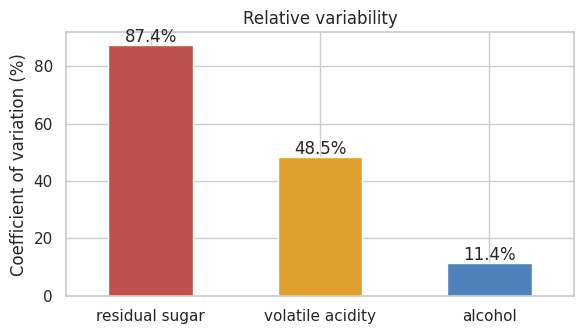

Greatest relative variability: residual sugar (CV = 87.4%)


In [3]:
cv = (desc["std dev"] / desc["mean"] * 100).rename("CV (%)").sort_values(ascending=False)
display(cv.to_frame())
ax = cv.plot(kind="bar", color=["#c0504d", "#e0a030", "#4f81bd"], figsize=(6, 3.5))
ax.set_ylabel("Coefficient of variation (%)"); ax.set_title("Relative variability"); plt.xticks(rotation=0)
for i, v in enumerate(cv): ax.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.tight_layout(); plt.show()
print(f"Greatest relative variability: {cv.idxmax()} (CV = {cv.max():.1f}%)")

**Interpretation:** residual sugar has by far the highest relative variability (CV ≈ 87 %), then volatile acidity (≈ 48 %), while alcohol is the most stable (≈ 11 %). Residual sugar differs hugely between dry and sweet wines, whereas alcohol is confined to a narrow band.

### 1c. Pearson correlation between alcohol and quality

In [4]:
r, p = stats.pearsonr(df["alcohol"], df["quality"])
rho, _ = stats.spearmanr(df["alcohol"], df["quality"])
print(f"Pearson r = {r:.4f}   (p-value = {p:.2e}, n = {len(df)})")
print(f"r² = {r**2:.4f}  -> alcohol alone explains about {r**2*100:.1f}% of the variance in quality")
print(f"Spearman rho (robustness check) = {rho:.4f}")

Pearson r = 0.4443   (p-value = 1.50e-312, n = 6497)
r² = 0.1974  -> alcohol alone explains about 19.7% of the variance in quality
Spearman rho (robustness check) = 0.4469


**Interpretation:** r ≈ **+0.44** is a **positive, moderate** relationship: higher-alcohol wines tend to receive higher quality scores. The p-value is effectively zero, but with 6,497 rows even small correlations are "significant", so the *size* of r matters more than the p-value. r² ≈ 0.20 means alcohol alone explains only about a fifth of the variation in quality. The Spearman value (≈ 0.45) agrees, so the result isn't driven by outliers. This is association, not proof that raising alcohol causes higher quality.

## Task 2 — Exploratory data analysis

### 2a. Histogram of quality scores

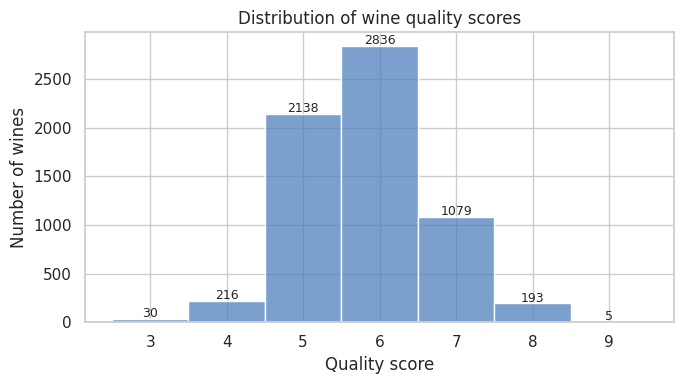

Mean = 5.818 | Median = 6 | Mode = 6 | Skew = 0.190
Share scoring 5-7: 93.2%


In [5]:
counts = df["quality"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df["quality"], discrete=True, color="#4f81bd", edgecolor="white", ax=ax)
for x, v in counts.items(): ax.text(x, v + 20, str(v), ha="center", fontsize=9)
ax.set_xlabel("Quality score"); ax.set_ylabel("Number of wines"); ax.set_title("Distribution of wine quality scores")
plt.tight_layout(); plt.show()
print("Mean = %.3f | Median = %d | Mode = %d | Skew = %.3f" % (df.quality.mean(), df.quality.median(), df.quality.mode()[0], df.quality.skew()))
print("Share scoring 5-7: %.1f%%" % (counts.loc[5:7].sum() / len(df) * 100))

**Interpretation:** the distribution is roughly bell-shaped but **discrete and concentrated**: scores run 3-9, with 5 and 6 the most common and about 90 % of wines scoring 5-7. Very poor (3-4) and excellent (8-9) wines are rare (only 5 wines score 9). The classes are **imbalanced**, which matters later because a regression model will be pulled toward the middle and struggle at the extremes.

### 2b. Box plot of alcohol by quality score

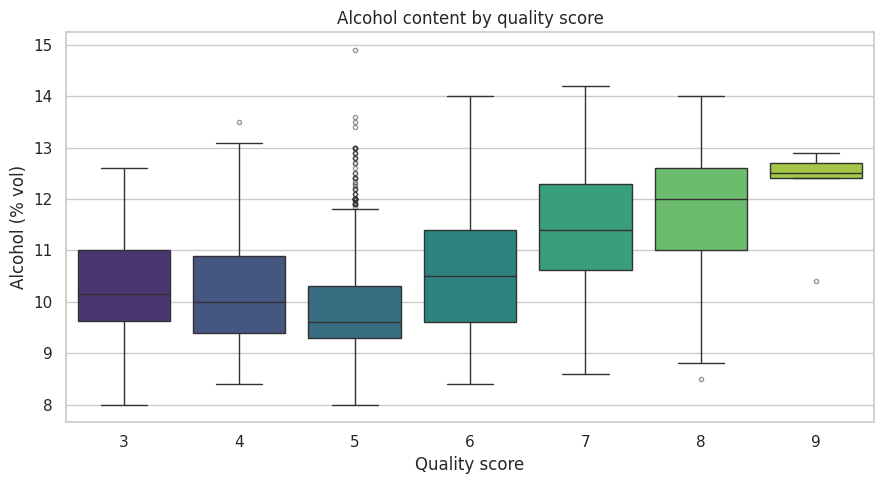

,count,median,mean,std,outliers (1.5×IQR)
quality,,,,,
3,30,10.1500,10.2150,1.1065,0
4,216,10.0000,10.1801,0.9859,1
5,2138,9.6000,9.8378,0.8144,55
6,2836,10.5000,10.5876,1.1265,0
7,1079,11.4000,11.3860,1.1993,0
8,193,12.0000,11.6788,1.2789,1
9,5,12.5000,12.1800,1.0134,1


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="quality", y="alcohol", palette="viridis", flierprops=dict(marker="o", markersize=3, alpha=.5), ax=ax)
ax.set_title("Alcohol content by quality score"); ax.set_xlabel("Quality score"); ax.set_ylabel("Alcohol (% vol)")
plt.tight_layout(); plt.show()

summary = df.groupby("quality")["alcohol"].agg(["count", "median", "mean", "std"])
q1, q3 = df.groupby("quality")["alcohol"].quantile(.25), df.groupby("quality")["alcohol"].quantile(.75)
iqr = q3 - q1
summary["outliers (1.5×IQR)"] = [int(((g < q1[k] - 1.5*iqr[k]) | (g > q3[k] + 1.5*iqr[k])).sum()) for k, g in df.groupby("quality")["alcohol"]]
summary

**Interpretation:**

- **Visible differences:** median alcohol falls from ~10.2 at score 3 to ~9.6 at score 5, then rises steadily: ~10.5 (6), ~11.4 (7), ~12.0 (8), ~12.5 (9). Beyond score 5 the trend is clearly upward, which agrees with the positive correlation.
- **Non-monotonic at the low end:** scores 3-4 are not lower in alcohol than score 5, so the relationship is not a perfect straight line, and the poorest wines are few and variable.
- **Outliers:** the 1.5×IQR rule flags 55 wines in the score-5 group (unusually strong wines that still scored only 5); every other group has at most 1. They are plausible wines, not obvious errors, so they are kept.
- Scores 3 and 9 have very few samples (30 and 5), so their boxes are unreliable.

### 2c. Correlation heatmap

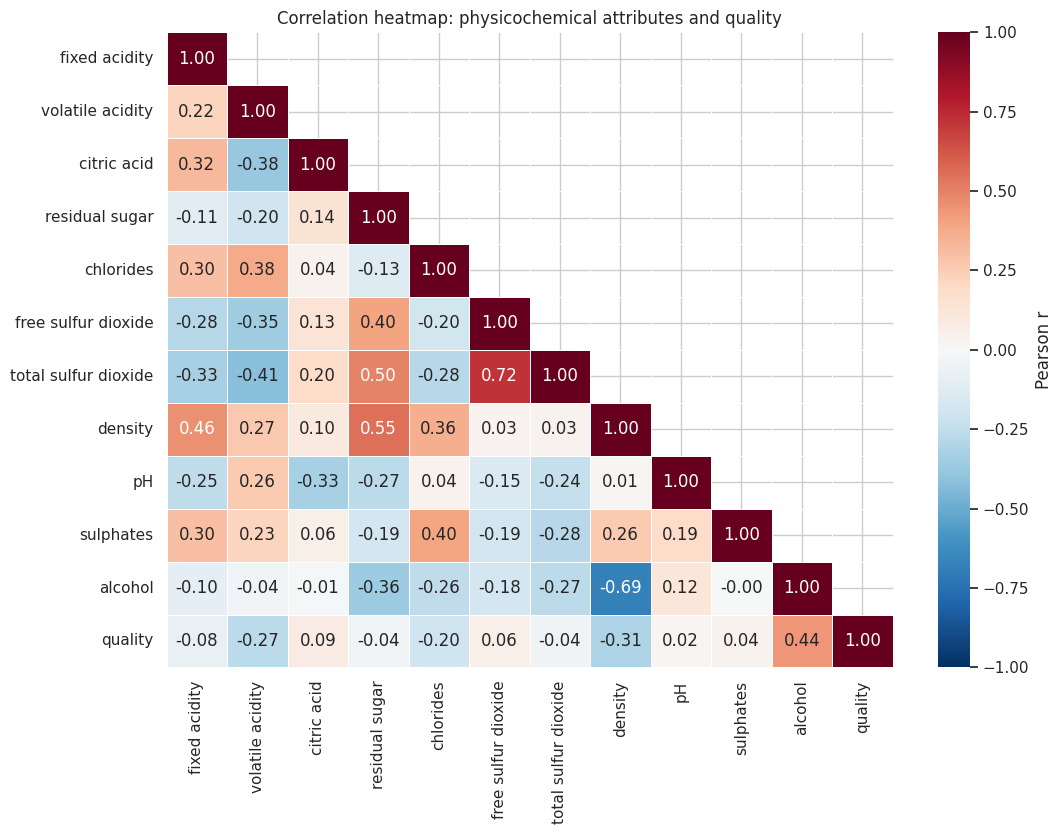

Strongest predictor-predictor correlations (relevant to multicollinearity):


,,r
total sulfur dioxide,free sulfur dioxide,0.7209
alcohol,density,-0.6867
density,residual sugar,0.5525
total sulfur dioxide,residual sugar,0.4955
density,fixed acidity,0.4589


In [7]:
corr = df[FEATURES + ["quality"]].corr(method="pearson")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=.5, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Correlation heatmap: physicochemical attributes and quality")
plt.tight_layout(); plt.show()

pairs = corr.loc[FEATURES, FEATURES].where(np.tril(np.ones((11, 11), dtype=bool), k=-1)).stack()
print("Strongest predictor-predictor correlations (relevant to multicollinearity):")
pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).to_frame("r")

**Interpretation:** the last row shows each attribute's correlation with quality. No single attribute is strongly correlated with it (|r| ≤ 0.44). Among predictors, the notable correlations are **free vs total SO₂ (≈ 0.72)**, **density vs alcohol (≈ −0.69)** and **density vs residual sugar (≈ +0.55)**. These overlaps foreshadow the multicollinearity discussion in Task 3d.

### 2d. Two attributes most strongly associated with quality

,Pearson r,|r|,direction
alcohol,0.4443,0.4443,positive
density,-0.3059,0.3059,negative
volatile acidity,-0.2657,0.2657,negative
chlorides,-0.2007,0.2007,negative
citric acid,0.0855,0.0855,positive
fixed acidity,-0.0767,0.0767,negative
free sulfur dioxide,0.0555,0.0555,positive
total sulfur dioxide,-0.0414,0.0414,negative
sulphates,0.0385,0.0385,positive
residual sugar,-0.0370,0.0370,negative


Top 2 by |r|: ['alcohol', 'density']


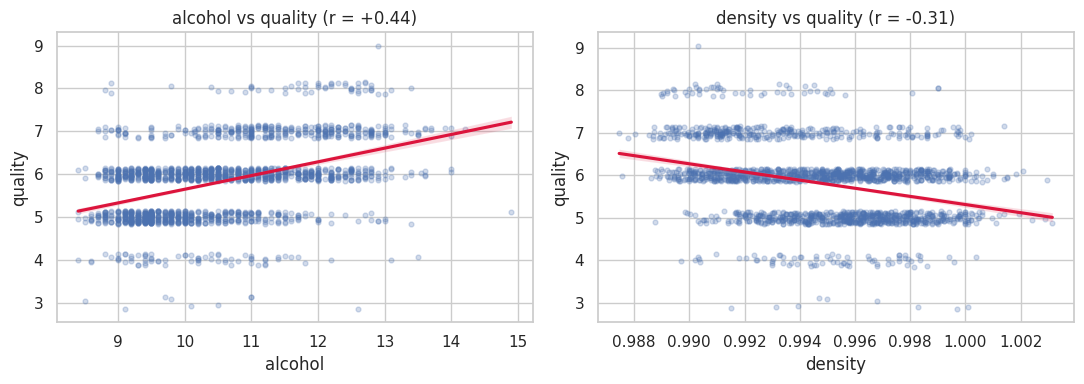

In [8]:
qcorr = corr["quality"].drop("quality")
ranked = qcorr.reindex(qcorr.abs().sort_values(ascending=False).index)
out = pd.DataFrame({"Pearson r": ranked, "|r|": ranked.abs(),
                    "direction": np.where(ranked > 0, "positive", "negative")})
display(out)
top2 = out.index[:2].tolist()
print("Top 2 by |r|:", top2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, c in zip(axes, top2):
    sns.regplot(data=df.sample(2000, random_state=RANDOM_STATE), x=c, y="quality", ax=a,
                x_jitter=0, y_jitter=.15, scatter_kws=dict(alpha=.25, s=12), line_kws=dict(color="crimson"))
    a.set_title(f"{c} vs quality (r = {qcorr[c]:+.2f})")
plt.tight_layout(); plt.show()

**Interpretation:**

1. **Alcohol, r ≈ +0.44 (positive):** stronger wines tend to score higher.
2. **Density, r ≈ −0.31 (negative):** denser wines tend to score lower.

Density is probably a *proxy*: it falls as alcohol rises (r ≈ −0.69), so part of its link to quality is shared with alcohol. **Volatile acidity (r ≈ −0.27)** comes next, with the negative sign you would expect, since it is associated with a vinegar-like taint.

## Task 3 — Predictive modelling

### 3a-b. Train/test split (80/20, `random_state=42`) and model fitting

In [9]:
X, y = df[FEATURES], df["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

coef = pd.DataFrame({"coefficient (raw units)": model.coef_}, index=FEATURES)
print("Intercept:", round(model.intercept_, 4))
coef

Train: 5197 rows | Test: 1300 rows
Intercept: 59.4198


,coefficient (raw units)
fixed acidity,0.0790
volatile acidity,-1.3508
citric acid,-0.1438
residual sugar,0.0459
chlorides,-0.3328
free sulfur dioxide,0.0070
total sulfur dioxide,-0.0027
density,-58.9451
pH,0.4828
sulphates,0.8084


### 3c. Test-set metrics

In [10]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)
metrics = pd.Series({"MAE": mae, "MSE": mse, "RMSE": rmse, "R²": r2}, name="Test set")
display(metrics.to_frame())

# Context for the numbers
baseline_mae  = mean_absolute_error(y_test, np.full_like(y_test, y_train.mean(), dtype=float))
within_half   = np.mean(np.abs(y_test - y_pred) <= 0.5)
within_one    = np.mean(np.abs(y_test - y_pred) <= 1.0)
exact_rounded = np.mean(np.round(y_pred) == y_test)
print(f"Baseline MAE (always predict the training mean): {baseline_mae:.3f}")
print(f"Within ±0.5 points: {within_half:.1%} | within ±1 point: {within_one:.1%} | exact after rounding: {exact_rounded:.1%}")
print(f"Share of test wines that are simply quality 6 (naive majority-class accuracy): {(y_test==6).mean():.1%}")

,Test set
MAE,0.5659
MSE,0.5467
RMSE,0.7394
R²,0.2598


Baseline MAE (always predict the training mean): 0.669
Within ±0.5 points: 53.9% | within ±1 point: 84.2% | exact after rounding: 53.9%
Share of test wines that are simply quality 6 (naive majority-class accuracy): 45.9%


**Interpretation:** R² ≈ **0.26**, so the model explains only about a quarter of the variance in quality. RMSE ≈ 0.74 and MAE ≈ 0.57 quality points. That is better than the naive baseline of always guessing the average (RMSE ≈ 0.86, MAE ≈ 0.67), but only by roughly 15 %. Predictions land within ±1 point about 84 % of the time, but only about 54 % match the true score once rounded, so most individual predictions are not precise enough to stand in for a tasting panel.

### 3d. Standardised coefficients and multicollinearity

Raw coefficients can't be compared across attributes because the units differ (density is ~1, alcohol is ~10, SO₂ is ~100). Standardising each predictor (z-scores, fitted on the **training** set only) makes each coefficient the change in quality per 1 standard deviation of that predictor.

Multicollinearity should be checked **first**, using the Variance Inflation Factor (VIF). A common rule of thumb is that VIF above 5 signals concern and above 10 serious trouble.

,VIF
density,15.5057
residual sugar,7.1964
fixed acidity,4.7412
alcohol,4.6162
total sulfur dioxide,2.9610
pH,2.4705
free sulfur dioxide,2.1591
volatile acidity,1.9362
chlorides,1.6457
citric acid,1.6136


,standardised coefficient,VIF
alcohol,0.3224,4.6162
residual sugar,0.2204,7.1964
volatile acidity,-0.2190,1.9362
density,-0.1773,15.5057
total sulfur dioxide,-0.1495,2.9610
free sulfur dioxide,0.1225,2.1591
sulphates,0.1202,1.5443
fixed acidity,0.1017,4.7412
pH,0.0771,2.4705
citric acid,-0.0208,1.6136


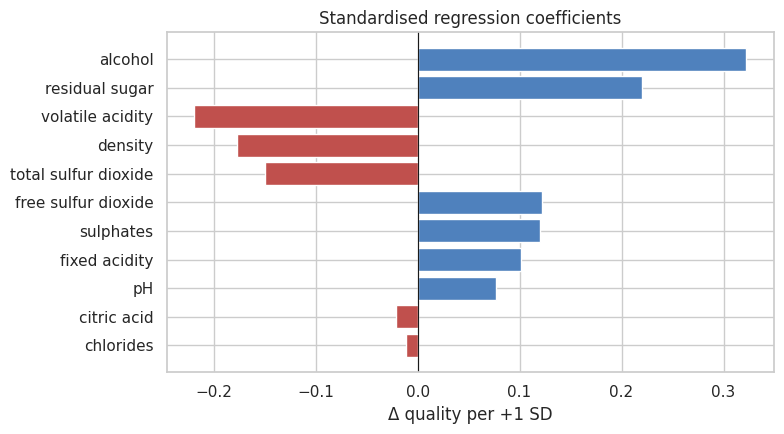

In [11]:
Xc = sm.add_constant(X_train)
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=FEATURES, name="VIF")
display(vif.sort_values(ascending=False).to_frame())

scaler = StandardScaler().fit(X_train)
model_std = LinearRegression().fit(scaler.transform(X_train), y_train)
std_coef = pd.Series(model_std.coef_, index=FEATURES, name="standardised coefficient")
std_tbl = std_coef.reindex(std_coef.abs().sort_values(ascending=False).index).to_frame()
std_tbl["VIF"] = vif
display(std_tbl)

fig, ax = plt.subplots(figsize=(8, 4.5))
s = std_tbl["standardised coefficient"].iloc[::-1]
ax.barh(s.index, s.values, color=np.where(s.values > 0, "#4f81bd", "#c0504d"))
ax.axvline(0, color="k", lw=.8); ax.set_title("Standardised regression coefficients"); ax.set_xlabel("Δ quality per +1 SD")
plt.tight_layout(); plt.show()

**Multicollinearity first:** **density has a VIF of about 15.5** (serious) and **residual sugar about 7.2**, with fixed acidity and alcohol both near 4.7. Density is largely explained by alcohol and sugar, which is exactly what the heatmap suggested. Coefficients of collinear variables are unstable and can take misleading signs or sizes.

**Top two by |standardised coefficient|:** **alcohol (≈ +0.32)** and **residual sugar (≈ +0.22)**, with volatile acidity (≈ −0.22) essentially tied with sugar.

- **Alcohol** has a moderate VIF and a coefficient consistent with its raw correlation, so it can be interpreted with confidence.
- **Residual sugar** is the problem: its raw correlation with quality is about zero (−0.04) yet its coefficient is clearly positive. That flip happens because density (VIF ≈ 15) is in the model. Holding density fixed, more sugar means less alcohol-driven density reduction, so the sugar coefficient partly absorbs density's effect. It should **not** be read as "sugar improves quality".

The check below removes density to show this.

In [12]:
feat_nd = [f for f in FEATURES if f != "density"]
sc_nd = StandardScaler().fit(X_train[feat_nd])
m_nd = LinearRegression().fit(sc_nd.transform(X_train[feat_nd]), y_train)
c_nd = pd.Series(m_nd.coef_, index=feat_nd)
cmp = pd.DataFrame({"with density": std_coef, "without density": c_nd})
display(cmp.reindex(cmp["with density"].abs().sort_values(ascending=False).index))
r2_nd = r2_score(y_test, m_nd.predict(sc_nd.transform(X_test[feat_nd])))
print(f"Test R² with density: {r2:.4f} | without density: {r2_nd:.4f}")

,with density,without density
alcohol,0.3224,0.4030
residual sugar,0.2204,0.1130
volatile acidity,-0.2190,-0.2409
density,-0.1773,NaN
total sulfur dioxide,-0.1495,-0.1355
free sulfur dioxide,0.1225,0.1228
sulphates,0.1202,0.1009
fixed acidity,0.1017,0.0244
pH,0.0771,0.0306
citric acid,-0.0208,-0.0214


Test R² with density: 0.2598 | without density: 0.2593


**Result:** without density, residual sugar's coefficient roughly halves (≈ 0.22 → 0.11) and drops out of the top three, and alcohol (≈ +0.40) and **volatile acidity (≈ −0.24)** emerge as the two clearest and most stable predictors. Test R² barely changes (≈ 0.259 vs 0.260), so density adds almost no predictive information beyond what the other variables already carry. Sugar's apparent influence in the full model is largely a collinearity artefact.

### 3e. Predicted vs actual scores and model limitations

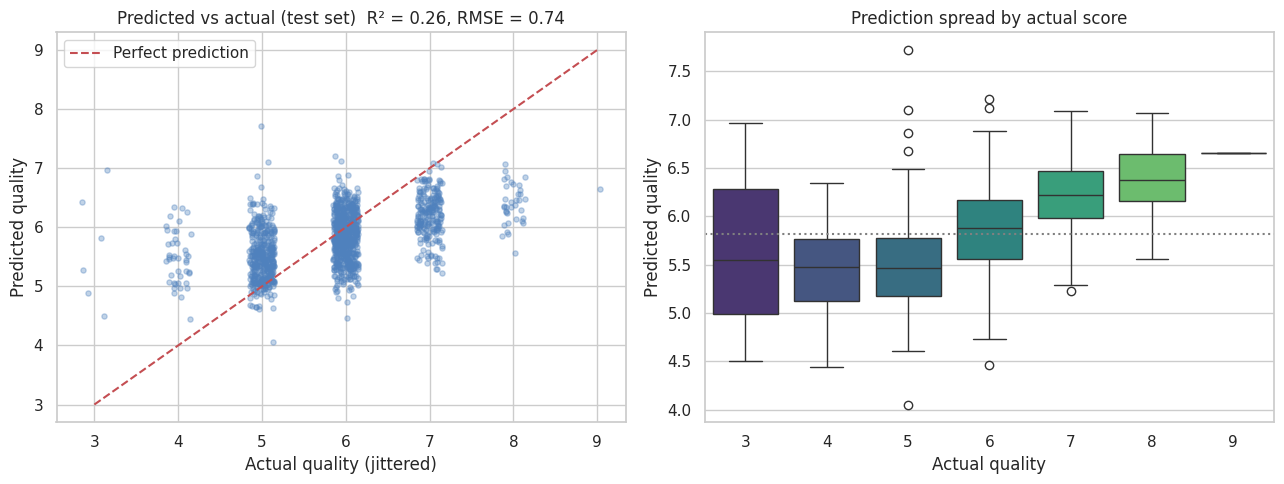

,n,mean_pred,MAE
actual,,,
3,6,5.6495,2.6495
4,43,5.4785,1.4785
5,402,5.5059,0.5333
6,597,5.8603,0.3521
7,215,6.2046,0.7971
8,36,6.3925,1.6075
9,1,6.6512,2.3488


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rng = np.random.default_rng(RANDOM_STATE)
ax = axes[0]
ax.scatter(y_test + rng.uniform(-.15, .15, len(y_test)), y_pred, alpha=.35, s=14, color="#4f81bd")
ax.plot([3, 9], [3, 9], "r--", label="Perfect prediction")
ax.set_xlabel("Actual quality (jittered)"); ax.set_ylabel("Predicted quality")
ax.set_title(f"Predicted vs actual (test set)  R² = {r2:.2f}, RMSE = {rmse:.2f}"); ax.legend()

ax = axes[1]
sns.boxplot(x=y_test.values, y=y_pred, palette="viridis", ax=ax)
ax.axhline(y_train.mean(), color="gray", ls=":")
ax.set_xlabel("Actual quality"); ax.set_ylabel("Predicted quality"); ax.set_title("Prediction spread by actual score")
plt.tight_layout(); plt.show()

err = pd.DataFrame({"actual": y_test.values, "pred": y_pred}); err["abs_err"] = (err.actual - err.pred).abs()
err.groupby("actual").agg(n=("abs_err", "size"), mean_pred=("pred", "mean"), MAE=("abs_err", "mean"))

**Limitations visible in the plots and table**

1. **Regression to the middle.** Predictions are squeezed into roughly 4-7.7. Poor wines (3-4) are over-predicted and excellent wines (8-9) are under-predicted; MAE is largest at the extremes. These are the wines a quality-control process most wants to catch.
2. **Low explanatory power.** Points form a wide cloud around the diagonal, with R² ≈ 0.26. Most variation in sensory quality is not captured by these 11 measurements.
3. **Linearity assumption.** The alcohol box plot showed a non-monotonic pattern at low scores, and the skewed variables (sugar, volatile acidity) probably need transforms or non-linear terms.
4. **Ordinal, discrete target.** Quality is an ordered category from panel scores, but linear regression outputs continuous values and treats the gap between scores as equal.
5. **Collinearity** (density, sugar, alcohol) makes individual coefficients unreliable even though overall predictions are fine.

### Robustness check: red vs white

In [14]:
rows = []
for name, d in df.groupby("wine_type"):
    a, b, c_, e = train_test_split(d[FEATURES], d["quality"], test_size=.2, random_state=RANDOM_STATE)
    m = LinearRegression().fit(a, c_); p = m.predict(b)
    rows.append({"type": name, "n": len(d), "mean quality": d.quality.mean(),
                 "MAE": mean_absolute_error(e, p), "RMSE": np.sqrt(mean_squared_error(e, p)), "R²": r2_score(e, p)})
pd.DataFrame(rows).set_index("type")

,n,mean quality,MAE,RMSE,R²
type,,,,,
red,1599,5.6360,0.5035,0.6245,0.4032
white,4898,5.8779,0.5863,0.7543,0.2653


Fitted separately, the red-wine model reaches R² ≈ 0.40 and the white-wine model ≈ 0.27. Red and white wines clearly have different quality drivers, so one pooled model is a compromise. Even the best of these is still well short of a replacement for sensory evaluation.

## Task 4 — Business decision-making

### 4a. Two measurements to prioritise in laboratory screening

1. **Alcohol content.** It is the strongest single correlate of quality (r ≈ +0.44), the largest standardised coefficient (≈ +0.32 with density, ≈ +0.40 without), and its box plots show a consistent rise in median from quality 6 upward. It is cheap and quick to measure, and its relationship stays stable when collinear variables are removed.
2. **Volatile acidity.** It has a clear negative association (r ≈ −0.27; standardised coefficient ≈ −0.22 to −0.24) and a low VIF (≈ 1.9), so its effect is not an artefact of collinearity. It also has a plausible chemical meaning, as a marker of spoilage and vinegar taint, and so works as a *warning* flag for defects.

*Why not density or residual sugar?* Density correlates more strongly with quality than volatile acidity does (r ≈ −0.31), but it mostly duplicates alcohol and sugar information (VIF ≈ 15.5). Residual sugar's positive coefficient is a collinearity artefact (raw r ≈ −0.04). Both are poor choices as stand-alone screening criteria, though density is still a cheap supporting measure.

### 4b. Can the model replace sensory evaluation? **No.**

Test-set evidence (random_state = 42):

In [15]:
verdict = pd.DataFrame({
    "Metric": ["R²", "RMSE", "MAE", "Within ±0.5", "Within ±1.0", "Exact (rounded)"],
    "Model": [r2, rmse, mae, within_half, within_one, exact_rounded],
    "Naive baseline": [0.0, np.sqrt(mean_squared_error(y_test, np.full_like(y_test, y_train.mean(), dtype=float))), baseline_mae, np.nan, np.nan, np.nan],
}).set_index("Metric")
verdict

,Model,Naive baseline
Metric,,
R²,0.2598,0.0000
RMSE,0.7394,0.8596
MAE,0.5659,0.6691
Within ±0.5,0.5392,NaN
Within ±1.0,0.8423,NaN
Exact (rounded),0.5392,NaN


- **R² ≈ 0.26:** about 74 % of the variation in quality is unexplained.
- **RMSE ≈ 0.74 and MAE ≈ 0.57** beat the naive baseline (0.86 and 0.67) only modestly. Since neighbouring quality grades differ by one point, errors of this size are comparable to the very differences management wants to detect.
- **Only about 54 % of predictions are exactly right after rounding**, versus 46 % from simply always guessing "6", and errors are largest at the extremes (mean absolute error ≈ 2.6 for score-3 wines and ≈ 1.6 for score-8 wines), which matter most.

The model is useful as a **screening aid**, for example flagging batches with low alcohol or high volatile acidity for closer tasting. It is not reliable enough to replace the sensory panel. A sensible process is lab screening first, with sensory evaluation retained for final decisions.

### 4c. Two limitations

1. **The target is subjective and coarse.** Quality is the median of a few experts' scores on a narrow, imbalanced scale (about 90 % of wines score 5-7, only 5 wines score 9), so the model has little signal at the extremes. The data also contains **1,179 duplicate rows**, which can leak between train and test sets and make test performance look slightly better than it truly is; there is no information on grape variety, vintage, brand or price either.
2. **The analytical approach is limited.** A single linear model with a fixed split assumes straight-line effects and independence between predictors, which the data violates (density-alcohol-sugar collinearity, skewed variables, different red/white behaviour). Results rest on one random split, with no cross-validation, and the findings are **associations**, not causal effects. Regularised or non-linear models (ridge, random forest, gradient boosting), log transforms, a wine-type interaction and cross-validation would be natural next steps.